# 실습03 · Freeze·Partial Fine-tuning 비교

> 원본 스크립트: `02_응용/03_finetune.py` (정답 주석본: `02_응용_주석/03_finetune.py`) · PPT 35쪽 · TODO A03

## 학습 목표
- `requires_grad`로 학습 범위를 정하고, Head-only와 Partial(마지막 Conv + Head)을 같은 조건에서 비교한다.
- `requires_grad=False`(갱신 여부)와 `eval()`(BatchNorm 통계 사용 방식)의 차이를 확인한다.
- valid 손실이 가장 낮은 epoch를 고르고 macro F1·triangle recall로 비교한다.

| 전략 | 학습 층 | 학습 파라미터 |
|---|---|---|
| head | `model[9]` Linear(256,3) | 768 + 3 = 771 |
| partial | `model[4]` Conv2d(8,16,3) + Head | 1,152 + 771 = 1,923 |

In [1]:
# ============================================================
# 0. 노트북 실행 환경 준비
# ============================================================

# 파일·폴더 경로를 객체로 다루는 Path
from pathlib import Path
# 결과 목록을 JSON 파일로 저장
import json
# 수치 배열 계산과 source 가중치(npz) 읽기
import numpy as np
# 결과 표(DataFrame) 생성·CSV 저장
import pandas as pd
# PyTorch: Tensor 연산, 자동 미분, 난수 seed
import torch
# 신경망 층(Conv2d, Linear 등)과 손실 함수
from torch import nn
# data/분할/클래스 폴더 구조를 데이터셋으로 읽는 ImageFolder
from torchvision.datasets import ImageFolder
# 이미지 변환(Resize, ToTensor) 묶음
from torchvision import transforms as tr
# 분류 평가 지표: 정확도, F1, 클래스별 보고서, 혼동행렬
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
# Matplotlib: 노트북 안에 이미지·그래프 표시
import matplotlib.pyplot as plt

# CPU 스레드 1개, seed 14 고정 -> .py 스크립트와 같은 재현 조건
torch.set_num_threads(1)
torch.manual_seed(14)

# 노트북은 자기 폴더(02_응용/)를 작업 경로로 실행된다
# - DATA : 원본 입력 (읽기만 하고 덮어쓰지 않음)
# - OUT  : 노트북이 만드는 결과물 전용 폴더 (스크립트의 outputs/와 분리)
DATA = Path("data")
OUT = Path("outputs_notebook")
OUT.mkdir(exist_ok=True)

# [0,1] RGB 32×32 -> 소형 source Backbone의 학습 입력 조건
# 주의: ImageNet Normalize는 넣지 않음
transform = tr.Compose([tr.Resize((32, 32)), tr.ToTensor()])
print("torch", torch.__version__, "/ 결과 폴더:", OUT)

torch 2.15.0+cu132 / 결과 폴더: outputs_notebook


In [2]:
# ============================================================
# 1. train / valid 이미지를 Tensor 묶음으로 준비
# ============================================================

# train : 학습에만 사용, valid : epoch·후보 비교에만 사용
# 주의: test 폴더는 읽지 않음
train = ImageFolder(DATA / "train", transform=transform)
valid = ImageFolder(DATA / "valid", transform=transform)

# torch.stack : 이미지 N장을 하나의 배치 Tensor로 쌓음
X_train = torch.stack([train[i][0] for i in range(len(train))])
y_train = torch.tensor(train.targets, dtype=torch.long)
X_valid = torch.stack([valid[i][0] for i in range(len(valid))])
y_valid = torch.tensor(valid.targets, dtype=torch.long)

print("classes:", train.class_to_idx)
print("X_train:", tuple(X_train.shape), "/ y_train 개수:", torch.bincount(y_train).tolist())
print("X_valid:", tuple(X_valid.shape), "/ y_valid 개수:", torch.bincount(y_valid).tolist())
print("값 범위:", round(float(X_train.min()), 3), "~", round(float(X_train.max()), 3))

classes: {'circle': 0, 'square': 1, 'triangle': 2}
X_train: (180, 3, 32, 32) / y_train 개수: [120, 40, 20]
X_valid: (90, 3, 32, 32) / y_valid 개수: [30, 30, 30]
값 범위: 0.024 ~ 0.937


In [3]:
# ============================================================
# 2. 모델 생성 함수: TinyShapeCNN Backbone + 새 Head
# ============================================================

def build_model():
    """source Backbone을 불러온 TinyShapeCNN을 만든다.

    - 0~8번 층: source_backbone.npz 값으로 덮어씀 (사전학습 Backbone)
    - 9번 층 Linear(256, 3): 현재 seed로 새로 초기화된 Head
    """
    model = nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
        nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(256, 3),
    )
    # allow_pickle=False : 수치 배열만 읽음 (파이썬 객체 복원 금지)
    with np.load(DATA / "source_backbone.npz", allow_pickle=False) as saved:
        state = model.state_dict()
        state.update({name: torch.from_numpy(saved[name].copy()) for name in saved.files})
    model.load_state_dict(state)
    return model


torch.manual_seed(14)
m = build_model()
x = X_valid[:1]
# 층을 하나씩 통과시키며 shape 변화를 확인
for i, layer in enumerate(m):
    x = layer(x)
    print(f"[{i}] {layer.__class__.__name__:<18} -> {tuple(x.shape)}")

[0] Conv2d             -> (1, 8, 32, 32)
[1] BatchNorm2d        -> (1, 8, 32, 32)
[2] ReLU               -> (1, 8, 32, 32)
[3] MaxPool2d          -> (1, 8, 16, 16)
[4] Conv2d             -> (1, 16, 16, 16)
[5] BatchNorm2d        -> (1, 16, 16, 16)
[6] ReLU               -> (1, 16, 16, 16)
[7] AdaptiveAvgPool2d  -> (1, 16, 4, 4)
[8] Flatten            -> (1, 256)
[9] Linear             -> (1, 3)


In [4]:
# ============================================================
# 3. 후보 하나를 학습·평가하는 함수 (스크립트 반복문 본문과 같은 로직)
# ============================================================

import time

def run_candidate(strategy, balance, keep=False):
    """(strategy, balance) 후보 하나를 8 epoch 학습하고 valid 지표를 반환한다.

    - strategy="head"    : 새 Head(model[9])만 학습
    - strategy="partial" : 마지막 Conv(model[4]) + Head 학습
    - balance="none"     : 기본 CrossEntropy
    - balance="weight"   : train 개수 역수 기반 클래스 가중치 CrossEntropy
    - keep=True          : 모델·확률·예측도 함께 반환
    """
    torch.manual_seed(14)
    model = build_model()

    # --------------------------------------------------------
    # 학습 범위: requires_grad로 갱신 대상 지정
    # --------------------------------------------------------
    for p in model.parameters():
        p.requires_grad = False
    for p in model[9].parameters():
        p.requires_grad = True
    if strategy == "partial":
        for p in model[4].parameters():
            p.requires_grad = True
    # BN running 통계 고정 (gradient는 끄지 않음)
    model.eval()

    # lr=0.003 : 학습률, weight_decay=0.0001 : 가중치 감쇠 규제
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=0.003, weight_decay=0.0001)
    counts = torch.bincount(y_train, minlength=3).float()
    inverse = 1.0 / counts
    class_weights = inverse / inverse.mean()
    criterion = nn.CrossEntropyLoss(weight=class_weights if balance == "weight" else None)

    # --------------------------------------------------------
    # 8 epoch 학습, valid 손실 최소 epoch 보관
    # --------------------------------------------------------
    history, best_loss = [], float("inf")
    started = time.perf_counter()
    for epoch in range(1, 9):
        optimizer.zero_grad()
        loss = criterion(model(X_train), y_train)
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            vl = nn.CrossEntropyLoss()(model(X_valid), y_valid).item()
        history.append({"strategy": strategy, "balance": balance, "epoch": epoch, "valid_loss": vl})
        if vl < best_loss:
            best_loss, best_epoch = vl, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    elapsed = time.perf_counter() - started

    # --------------------------------------------------------
    # best epoch 복원 후 valid 평가
    # --------------------------------------------------------
    model.load_state_dict(best_state)
    with torch.no_grad():
        prob = model(X_valid).softmax(1)
        pred = prob.argmax(1)
    report = classification_report(y_valid, pred, labels=[0, 1, 2], output_dict=True, zero_division=0)
    row = {
        "strategy": strategy,
        "balance": balance,
        "params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "best_epoch": best_epoch,
        "accuracy": accuracy_score(y_valid, pred),
        "macro_f1": f1_score(y_valid, pred, labels=[0, 1, 2], average="macro", zero_division=0),
        "triangle_recall": report["2"]["recall"],
        "seconds": elapsed,
    }
    if keep:
        return row, history, class_weights, model, prob, pred
    return row, history, class_weights

## 4. requires_grad와 eval()은 서로 다르다

`eval()` 상태에서도 gradient는 계산된다. 갱신 여부는 `requires_grad`가 정한다.

In [5]:
# ============================================================
# 4. requires_grad=False와 eval()의 차이 확인
# ============================================================

torch.manual_seed(14)
m = build_model()
for p in m.parameters():
    p.requires_grad = False
for p in m[9].parameters():
    p.requires_grad = True
m.eval()

running_before = m[5].running_mean.clone()
loss = nn.CrossEntropyLoss()(m(X_train), y_train)
loss.backward()
print("eval() 상태에서 Head grad 존재:", m[9].weight.grad is not None)
print("고정된 Conv(model[4]) grad:", m[4].weight.grad)
print("BN running_mean 변화 없음:", torch.equal(running_before, m[5].running_mean))

# train() 모드로 한 번 순전파하면 running 통계가 바뀐다 (requires_grad와 무관)
m.train()
with torch.no_grad():
    m(X_train)
print("train() 순전파 후 running_mean 변화:", not torch.equal(running_before, m[5].running_mean))

eval() 상태에서 Head grad 존재: True
고정된 Conv(model[4]) grad: None
BN running_mean 변화 없음: True
train() 순전파 후 running_mean 변화: True


## 5. TODO A03 · 두 전략 비교

In [6]:
# ============================================================
# 5. TODO A03: Head-only, Partial 두 전략 비교
# ============================================================

experiments = [("head", "none"), ("partial", "none")]
rows, all_history = [], []
for strategy, balance in experiments:
    row, history, _ = run_candidate(strategy, balance)
    rows.append(row)
    all_history += history

table = pd.DataFrame(rows)
table.to_csv(OUT / "finetune_comparison.csv", index=False)
print(table.drop(columns="seconds").round(4).to_string(index=False))
print("시간은 finetune_comparison.csv에 기록: 기기별로 달라짐")

strategy balance  params  best_epoch  accuracy  macro_f1  triangle_recall
    head    none     771           8    0.8111    0.8038           0.5000
 partial    none    1923           8    0.9556    0.9562           0.9333
시간은 finetune_comparison.csv에 기록: 기기별로 달라짐


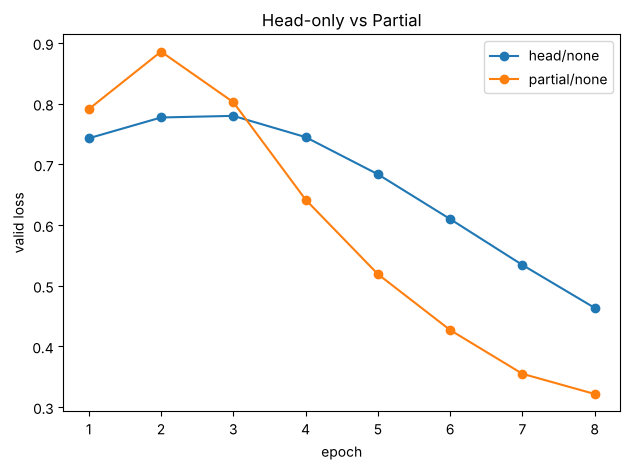

strategy    head  partial
epoch                    
1         0.7431   0.7911
2         0.7773   0.8859
3         0.7800   0.8026
4         0.7450   0.6420
5         0.6838   0.5192
6         0.6100   0.4271
7         0.5343   0.3549
8         0.4635   0.3217


In [7]:
# epoch별 valid 손실 곡선
hist = pd.DataFrame(all_history)
for (s, b), g in hist.groupby(["strategy", "balance"], sort=False):
    plt.plot(g["epoch"], g["valid_loss"], marker="o", label=f"{s}/{b}")
plt.xlabel("epoch"); plt.ylabel("valid loss"); plt.legend(); plt.title("Head-only vs Partial")
plt.tight_layout()
plt.savefig(OUT / "p03_valid_loss.png", dpi=100)
plt.show()
print(hist.pivot(index="epoch", columns="strategy", values="valid_loss").round(4))

## 정리 · README 정답 예와 대조

README 정답 실행 예: head 771 / 8 / 0.8111 / 0.8038 / 0.5000, partial 1923 / 8 / 0.9556 / 0.9562 / 0.9333.

- **requires_grad=False와 eval():** `requires_grad=False`는 그 파라미터의 기울기 계산·갱신을 끈다. `eval()`은 BatchNorm이 배치 통계 대신 저장된 running 통계를 쓰게 하고 Dropout을 끄는 모드 전환일 뿐, gradient를 끄지 않는다(위 4번 셀에서 eval 상태로 Head grad가 계산됨).
- **partial이 여는 층:** 마지막 Conv `model[4]` Conv2d(8→16, 3×3) 1,152개를 Head와 함께 연다. BatchNorm affine은 응용에서 열지 않는다.